# 2. Exploratory analysis of indicator fields

Builds `df_norm` (a normalized copy; `df` is unchanged) and explores the 842 indicator columns.

### Run the earlier steps
Loads the variables this notebook needs (`df`, `df_norm`, ...) by running `01_load_data.ipynb` (which runs the steps before it). Output is hidden.

In [1]:
%%capture
%run -i "01_load_data.ipynb"

## 2.1 Normalize Boolean encodings and summarize indicator fields

In [2]:
# Normalize common representations without modifying the original df
def normalize_boolean_value(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if isinstance(value, (int, float, np.integer, np.floating)):
        if value == 1:
            return True
        if value == 0:
            return False
        return value

    value_str = str(value).strip().lower()

    if value_str in {"true", "1", "yes", "y"}:
        return True
    if value_str in {"false", "0", "no", "n"}:
        return False
    if value_str in {"", "nan", "none", "null"}:
        return np.nan

    return value


df_norm = df.copy()

for col in df_norm.columns:
    df_norm[col] = df_norm[col].map(normalize_boolean_value)

# Identify columns that contain only True, False, and missing values
binary_cols = [
    col for col in df_norm.columns
    if set(df_norm[col].dropna().unique()).issubset({True, False})
    and df_norm[col].notna().any()
]

print("Binary columns:", len(binary_cols))

# Count the three cases separately
binary_summary = pd.DataFrame({
    "True_count": [
        int(df_norm[col].eq(True).sum()) for col in binary_cols
    ],
    "False_count": [
        int(df_norm[col].eq(False).sum()) for col in binary_cols
    ],
    "Missing_count": [
        int(df_norm[col].isna().sum()) for col in binary_cols
    ],
    "True_pct_all_rows": [
        100 * df_norm[col].eq(True).mean() for col in binary_cols
    ],
    "True_pct_nonmissing": [
        100 * df_norm[col].eq(True).sum()
        / df_norm[col].notna().sum()
        for col in binary_cols
    ]
}, index=binary_cols)

binary_summary.index.name = "Feature"
binary_summary = binary_summary.sort_values(
    "True_count", ascending=False
)

display(binary_summary.head(30).round(2))

Binary columns: 842


,True_count,False_count,Missing_count,True_pct_all_rows,True_pct_nonmissing
Feature,,,,,
Person PersonOrganization / Carrier / Railroad 1,10214,0,47,99.54,100.00
Assessments ContributingFactors / Human Factors,10141,0,120,98.83,100.00
Events Anomaly / Procedural Deviation - Operations Policy,10103,0,158,98.46,100.00
Person Craft / Transportation 1,10074,0,187,98.18,100.00
Person Qualification / 218 Railroad Operating Practices 1,9972,0,289,97.18,100.00
Train / Equipment TypeOfOperation / Passenger / Commuter 1,9714,0,547,94.67,100.00
Events Detector.Person / Train Crew,9439,0,822,91.99,100.00
Train / Equipment TypeOfCommunications / Radio 1,9358,0,903,91.20,100.00
Assessments PrimaryProblem / Human Factors,9318,0,943,90.81,100.00


## 2.2 Most frequent indicators

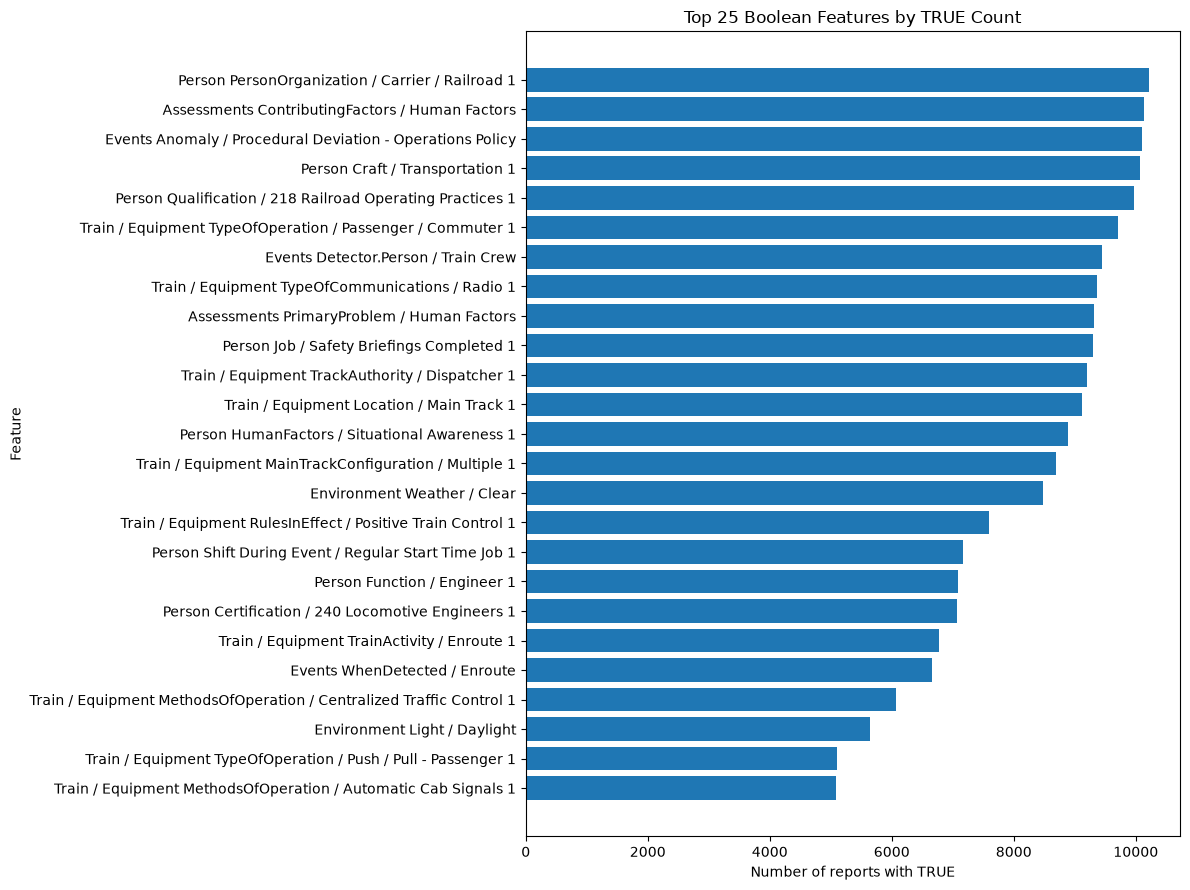

In [3]:
top_n = 25

plot_data = binary_summary.head(top_n).sort_values("True_count")

plt.figure(figsize=(12, 9))
plt.barh(plot_data.index, plot_data["True_count"])
plt.xlabel("Number of reports with TRUE")
plt.ylabel("Feature")
plt.title(f"Top {top_n} Boolean Features by TRUE Count")
plt.tight_layout()
plt.show()

## 2.3 Rare indicators (TRUE in < 1% of observed rows)

In [4]:
binary_summary["True_rate_nonmissing"] = (
    binary_summary["True_pct_nonmissing"] / 100
)

print("Rare indicators: TRUE in fewer than 1% of observed rows")
display(
    binary_summary[
        binary_summary["True_rate_nonmissing"] < 0.01
    ].sort_values("True_count").head(30)
)

Rare indicators: TRUE in fewer than 1% of observed rows


,True_count,False_count,Missing_count,True_pct_all_rows,True_pct_nonmissing,True_rate_nonmissing
Feature,,,,,,
Train / Equipment MaintenanceStatus / Maintenance Deferred 2,0,1,10260,0.0,0.0,0.0


## 2.4 Indicator families

In [5]:
def get_family(col):
    # Use the first section of hierarchical column names
    return str(col).split(" / ")[0].strip()

family_summary = pd.DataFrame({
    "Feature": binary_cols,
    "Family": [get_family(c) for c in binary_cols],
    "TRUE_count": [int(df_norm[c].eq(True).sum()) for c in binary_cols],
    "Missing_count": [int(df_norm[c].isna().sum()) for c in binary_cols],
})

family_stats = (
    family_summary.groupby("Family")
    .agg(
        Number_of_features=("Feature", "count"),
        Sum_of_TRUE=("TRUE_count", "sum"),
        Average_TRUE_per_feature=("TRUE_count", "mean"),
        Average_missing_per_feature=("Missing_count", "mean")
    )
    .sort_values("Number_of_features", ascending=False)
)

display(family_stats.round(2))

,Number_of_features,Sum_of_TRUE,Average_TRUE_per_feature,Average_missing_per_feature
Family,,,,
Train,175,122375,699.29,9532.40
Person Function,148,14055,94.97,10166.03
Person Location Of Person,102,15406,151.04,10109.96
Person Qualification,63,15456,245.33,10015.67
Person HumanFactors,60,23065,384.42,9876.58
Events Anomaly,42,29206,695.38,9565.62
Person Shift During Event,39,12945,331.92,9929.08
Events Result.General,23,10482,455.74,9805.26
Person Craft,23,13733,597.09,9663.91


## 2.5 Numeric columns

In [6]:
# Select columns already stored as numeric, excluding booleans
numeric_cols = [
    col for col in df.columns
    if pd.api.types.is_numeric_dtype(df[col])
    and not pd.api.types.is_bool_dtype(df[col])
]

print("Numeric columns:", len(numeric_cols))

numeric_summary = df[numeric_cols].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

numeric_summary["Missing_count"] = df[numeric_cols].isna().sum()
numeric_summary["Unique_values"] = df[numeric_cols].nunique(dropna=True)

display(numeric_summary.round(2))

Numeric columns: 1084


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,Missing_count,Unique_values
ACN,10261.0,27032.95,10019.82,3043.0,3610.6,20936.0,27762.0,35240.0,41321.0,42519.6,42788.0,0,10261
Environment WorkEnvironmentFactors / Air Quality,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
Person C3RS Report Number / Accession Number 1,10261.0,27032.95,10019.82,3043.0,3610.6,20936.0,27762.0,35240.0,41321.0,42519.6,42788.0,0,10261
Person PersonOrganization / Contracted Service 1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
Person Function / Carpenter 1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Events Result.Engineering / Other,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
Events Result.Mechanical / AAR / APTA Early Warning,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
Events Result.Mechanical / Other,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0
Assessments PrimaryProblem / Incorrect / Not Installed / Unavailable Part,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10261,0


## 2.6 Most frequent indicators within key families

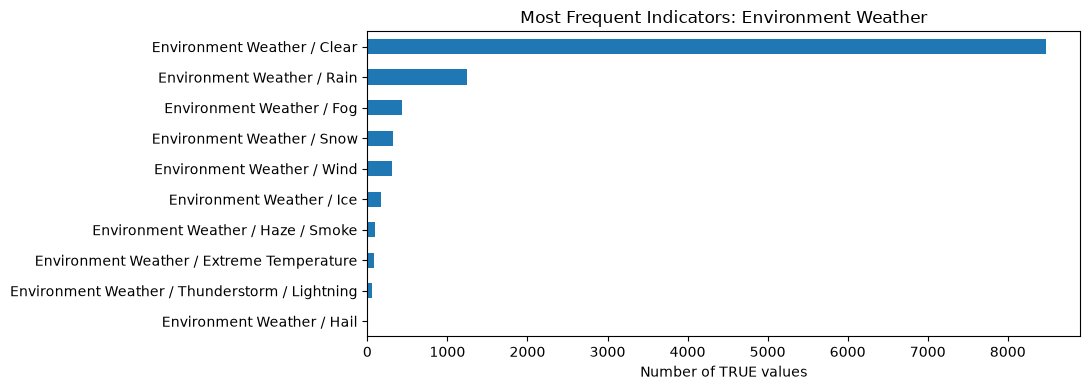

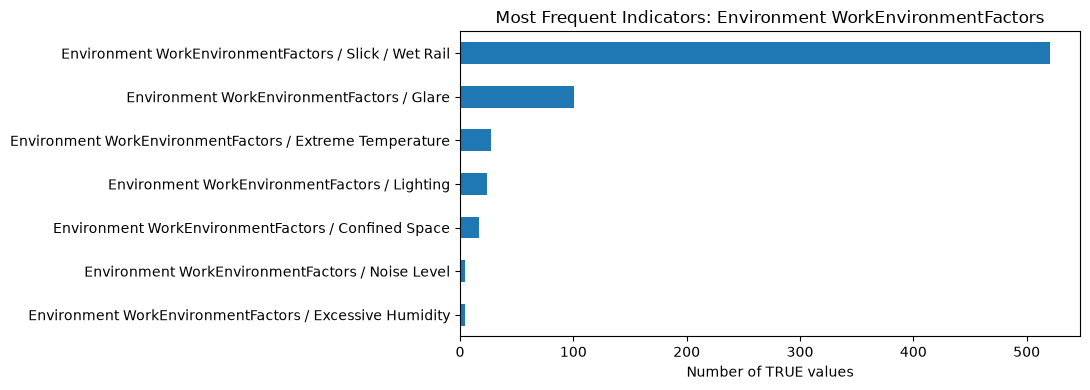

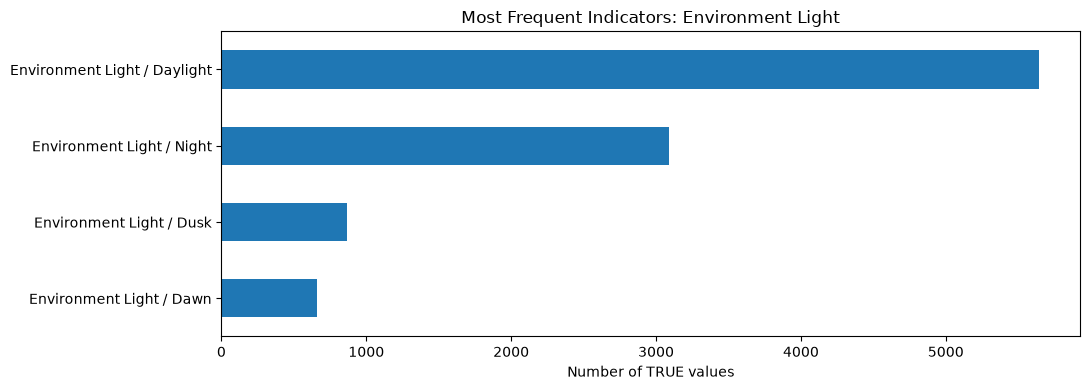

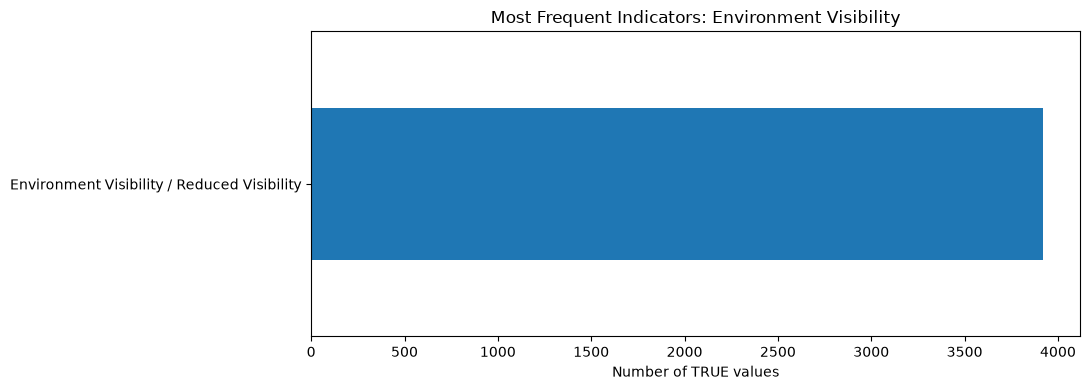

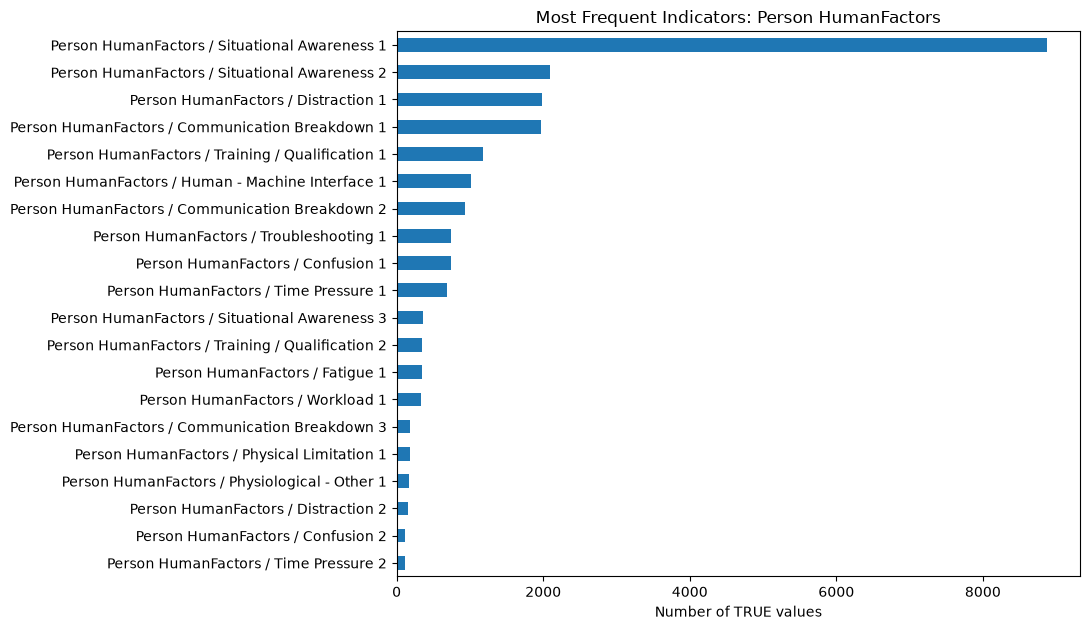

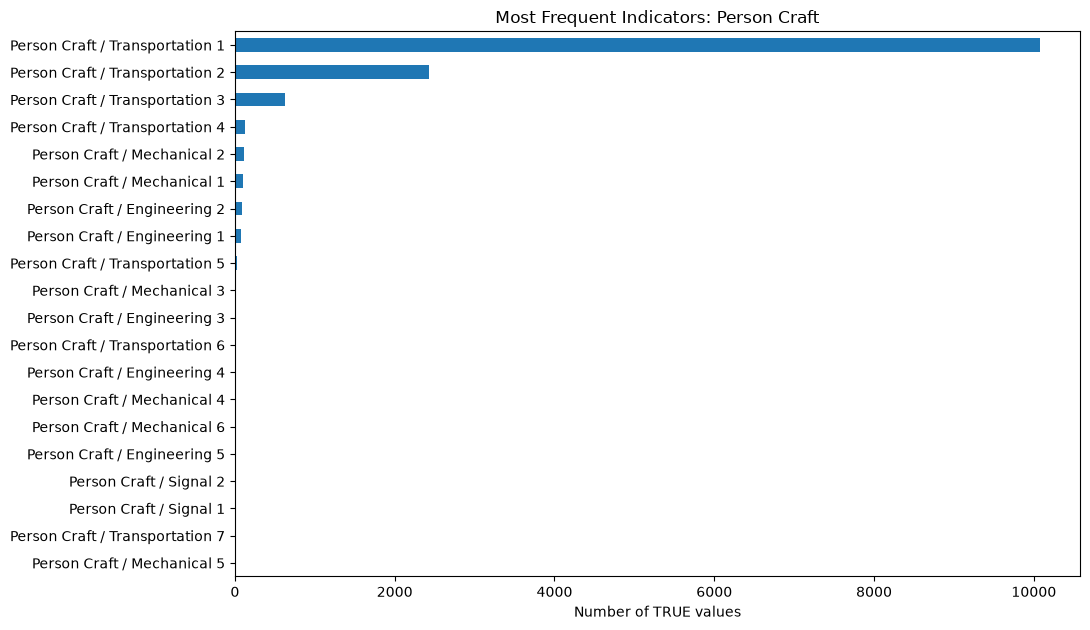

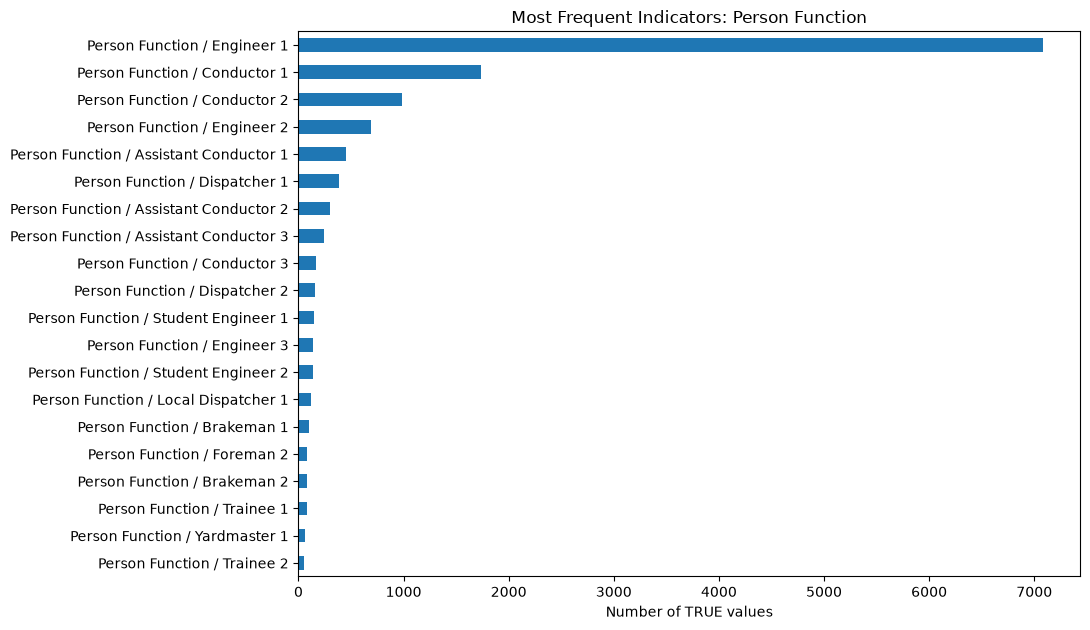

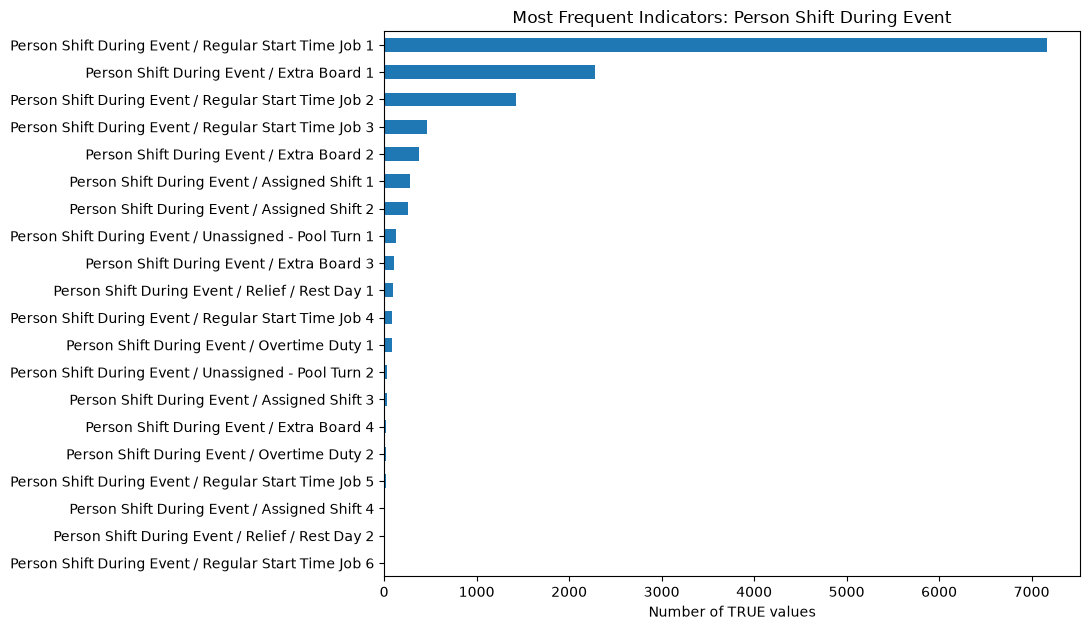

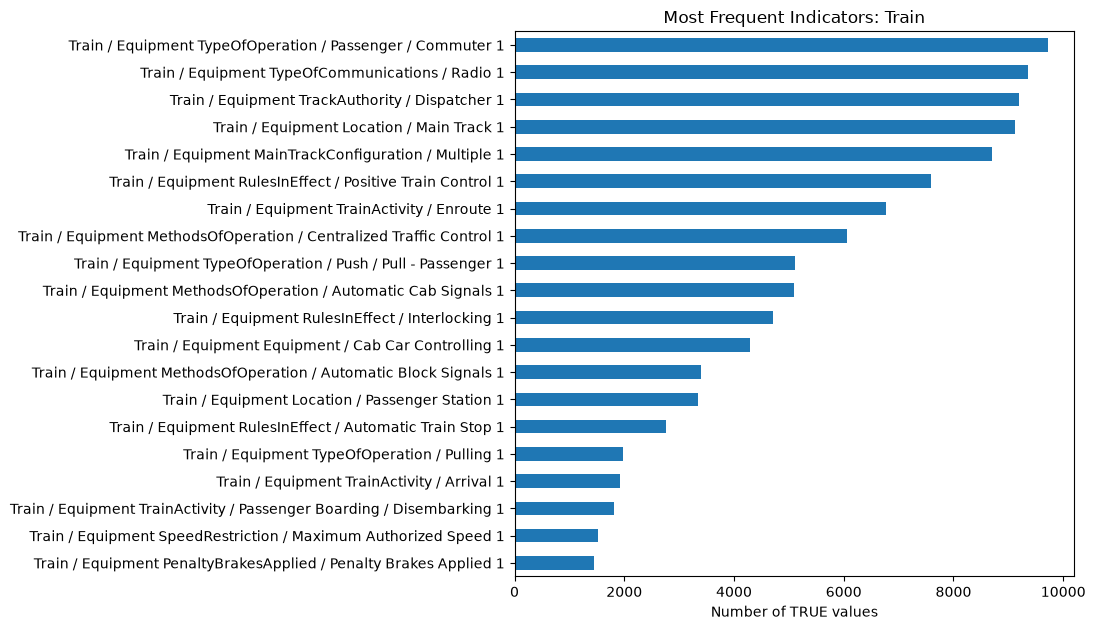

In [7]:
families_of_interest = [
    "Environment Weather",
    "Environment WorkEnvironmentFactors",
    "Environment Light",
    "Environment Visibility",
    "Person HumanFactors",
    "Person Experience",
    "Person Craft",
    "Person Function",
    "Person Shift During Event",
    "Train"
]

for family in families_of_interest:
    cols = [
        c for c in binary_cols
        if c.startswith(family + " / ")
    ]

    if not cols:
        continue

    counts = df_norm[cols].eq(True).sum().sort_values().tail(20)

    plt.figure(figsize=(11, max(4, len(counts) * 0.32)))
    counts.sort_values().plot(kind="barh")
    plt.xlabel("Number of TRUE values")
    plt.title(f"Most Frequent Indicators: {family}")
    plt.tight_layout()
    plt.show()

## 2.7 Most correlated indicator pairs

In [8]:
# Correlation matrix
corr_input = df_norm[binary_cols].eq(True).astype(float)
corr_input = corr_input.loc[:, corr_input.std() > 0]   # constant columns have no correlation
binary_corr = corr_input.corr()
print("Correlation matrix:", binary_corr.shape)

Correlation matrix: (841, 841)


In [9]:
corr_pairs = (
    binary_corr.where(
        np.triu(np.ones(binary_corr.shape), k=1).astype(bool)
    )
    .stack()
    .rename("Correlation")
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

corr_pairs["Absolute_correlation"] = corr_pairs["Correlation"].abs()

display(
    corr_pairs.sort_values(
        "Absolute_correlation", ascending=False
    ).head(25).round(3)
)

,Feature_1,Feature_2,Correlation,Absolute_correlation
344401,Person Qualification / 232 Brake System Safety...,Person Function / Foreman 6,1.0,1.0
344413,Person Qualification / 232 Brake System Safety...,Person Location Of Person / Shop 6,1.0,1.0
344420,Person Qualification / 232 Brake System Safety...,Person Qualification / 229 Railroad Locomotive...,1.0,1.0
344421,Person Qualification / 232 Brake System Safety...,Person Qualification / 231 Railroad Safety App...,1.0,1.0
396583,Person Location Of Person / Dispatch Center 7,Person Qualification / 218 Railroad Operating ...,1.0,1.0
346078,Person Qualification / 238 Passenger Equipment...,Person Function / Carman 6,1.0,1.0
336010,Person Location Of Person / Shop 5,Person Qualification / 229 Railroad Locomotive...,1.0,1.0
336011,Person Location Of Person / Shop 5,Person Qualification / 231 Railroad Safety App...,1.0,1.0
336003,Person Location Of Person / Shop 5,Person Location Of Person / Shop 6,1.0,1.0
335968,Person Location Of Person / Shop 5,Person Qualification / 232 Brake System Safety...,1.0,1.0


## 2.8 Find the fatigue and hours-into-shift columns

In [10]:
# Search columns by name
for col in df.columns:
    if "Hours Into Shift" in col or "Fatigue" in col:
        print(col)

Person Shift During Event / Hours Into Shift 1
Person HumanFactors / Fatigue 1
Person Shift During Event / Hours Into Shift 2
Person HumanFactors / Fatigue 2
Person Shift During Event / Hours Into Shift 3
Person HumanFactors / Fatigue 3
Person Shift During Event / Hours Into Shift 4
Person HumanFactors / Fatigue 4
Person Shift During Event / Hours Into Shift 5
Person HumanFactors / Fatigue 5
Person Shift During Event / Hours Into Shift 6
Person HumanFactors / Fatigue 6
Person Shift During Event / Hours Into Shift 7
Person HumanFactors / Fatigue 7
Person Shift During Event / Hours Into Shift 8
Person HumanFactors / Fatigue 8
Person Shift During Event / Hours Into Shift 9
Person HumanFactors / Fatigue 9
Person Shift During Event / Hours Into Shift 10
Person HumanFactors / Fatigue 10


## 2.9 Hours into shift vs. reported fatigue

                count      mean       std  min  25%  50%  75%   max
Fatigue                                                            
Fatigue = TRUE  319.0  6.187931  3.335013  0.0  3.4  6.0  9.0  14.0


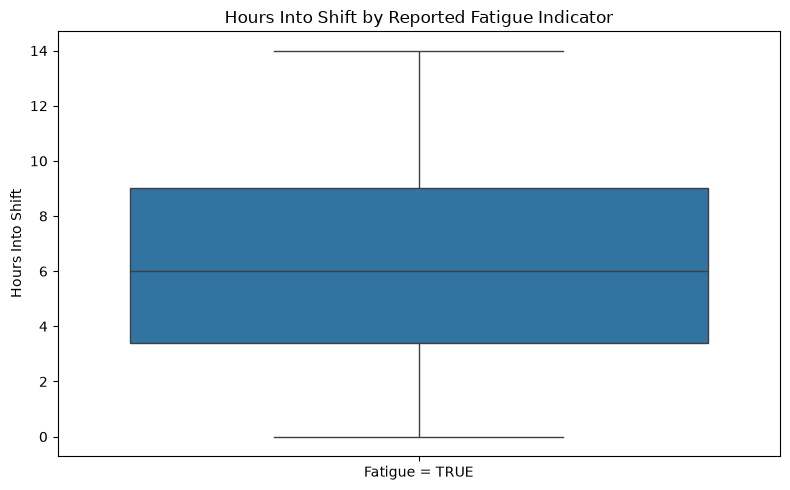

In [11]:
# Replace these with the exact names printed above
target_col = "Person HumanFactors / Fatigue 1"
numeric_col = "Person Shift During Event / Hours Into Shift 1"

if target_col in df_norm.columns and numeric_col in df.columns:
    comparison = pd.DataFrame({
        "target": df_norm[target_col],
        "numeric": pd.to_numeric(df[numeric_col], errors="coerce")
    }).dropna()

    comparison = comparison[
        comparison["target"].isin([True, False])
    ]

    comparison["Fatigue"] = comparison["target"].map({
        True: "Fatigue = TRUE",
        False: "Fatigue = FALSE"
    })

    print(comparison.groupby("Fatigue")["numeric"].describe())

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=comparison, x="Fatigue", y="numeric")
    plt.title("Hours Into Shift by Reported Fatigue Indicator")
    plt.xlabel("")
    plt.ylabel("Hours Into Shift")
    plt.tight_layout()
    plt.show()
else:
    print("Check the exact column names before plotting.")